# PlantAdvisor: подготовка и проверка SFT-датасета

**Генеративные языковые модели · Подготовка данных**

Цель работы — подготовить русскоязычный набор диалогов для дообучения `Qwen2.5-3B-Instruct` и проверить его структуру, состав и обособленность от контрольной выборки. Предметная область — уход за комнатными растениями и анализ проблем по описанию симптомов.

Набор содержит 400 синтетических примеров двух категорий: `care` — рекомендации по уходу и `diagnosis` — разбор симптомов. Для обучения выделено 360 примеров, для валидации — 40. Отдельный контрольный набор из 30 вопросов не включён ни в одну из этих выборок.

Примеры построены на сценариях ухода и диагностики с опорой на справочные материалы Royal Horticultural Society и университетских служб Extension. Ссылки описывают общие принципы ухода; индивидуальная экспертная проверка всех ответов не проводилась. Ноутбук анализирует готовую вторую редакцию набора и не требует скриптов его первоначального формирования.

Порядок работы: загрузка файлов, анализ распределений, проверка формата и уникальности, сопоставление с контрольными вопросами, подготовка формы ручной проверки и проверка загрузки через Hugging Face Datasets. Результат — файлы `train.jsonl` и `validation.jsonl`, таблицы аудита и график состава выборки.


In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 1. Среда выполнения и исходные файлы

Ноутбук рассчитан на Google Colab с обычной CPU-средой; GPU не требуется. Первая ячейка подключает Google Drive. Рабочий каталог — `MyDrive/plant-advisor/`.

Для повторного запуска поместите архив `plant_advisor_sft_data_v2.zip` в этот каталог либо заранее скопируйте туда каталог `data/` из репозитория. Должны присутствовать `train.jsonl`, `validation.jsonl`, `sft_metadata.jsonl`, `sft_provenance.csv`, `sources.csv` и `eval_questions.jsonl`. Если необходимых файлов нет, ячейка настройки извлекает их из архива. При наличии всех файлов используются данные из `data/`; перед запуском следует проверить, что это нужная редакция набора.

Для анализа используются `pandas`, `matplotlib`, `scikit-learn` и `datasets`. Если какого-либо пакета нет в среде, его можно установить командой `%pip install pandas matplotlib scikit-learn datasets`. Сохранённые ниже выводы позволяют изучить результаты без повторного выполнения ячеек.


In [13]:
from __future__ import annotations

import csv
import hashlib
import json
import re
import zipfile
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

try:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_DIR = Path("/content/drive/MyDrive/plant-advisor")
except ImportError:
    PROJECT_DIR = Path.cwd()

DATA_DIR = PROJECT_DIR / "data"
RESULTS_DIR = PROJECT_DIR / "results" / "dataset"
ARCHIVE_PATH = PROJECT_DIR / "plant_advisor_sft_data_v2.zip"

DATA_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

expected = [
    "data/train.jsonl", "data/validation.jsonl", "data/sft_metadata.jsonl",
    "data/sft_provenance.csv", "data/sources.csv", "data/eval_questions.jsonl",
]

if not all((PROJECT_DIR / name).exists() for name in expected):
    if not ARCHIVE_PATH.exists():
        raise FileNotFoundError(
            f"Нет исходных данных в {DATA_DIR}. Скопируйте {ARCHIVE_PATH.name} в {PROJECT_DIR}."
        )
    with zipfile.ZipFile(ARCHIVE_PATH) as archive:
        for name in expected:
            if name not in archive.namelist():
                raise FileNotFoundError(f"Архив не содержит {name}")
            target = PROJECT_DIR / name
            target.parent.mkdir(parents=True, exist_ok=True)
            content = archive.read(name)
            if target.exists() and target.read_bytes() != content:
                if name == "data/eval_questions.jsonl":
                    raise ValueError("Тестовые вопросы в Drive отличаются от архива. Сверьте версии перед продолжением.")
            target.write_bytes(content)

print("Каталог проекта:", PROJECT_DIR)
print("Обучающие данные:", DATA_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Каталог проекта: /content/drive/MyDrive/plant-advisor
Обучающие данные: /content/drive/MyDrive/plant-advisor/data


## 2. Формат и загрузка данных

Каждая строка `train.jsonl` и `validation.jsonl` — JSON-объект с полем `messages`: сначала сообщение пользователя (`user`), затем ответ консультанта (`assistant`). Такая структура подходит для загрузки в Hugging Face Datasets.

Файл `sft_metadata.jsonl` содержит ID примера, растение, категорию задачи, сценарий, текст вопроса и ответа, источники и назначенную выборку. Порядок записей внутри каждой выборки согласован с обучающими файлами. Происхождение примеров также представлено в `sft_provenance.csv`, а справочник источников — в `sources.csv`.

После загрузки проверяются размеры выборок и число представленных растений и сценариев. Контрольные вопросы читаются отдельно.


In [14]:
def read_jsonl(path: Path) -> list[dict]:
    """Прочитать записи JSONL с номерами строк в сообщениях об ошибках."""
    result = []
    with path.open(encoding="utf-8") as file:
        for number, line in enumerate(file, start=1):
            if line.strip():
                try:
                    result.append(json.loads(line))
                except json.JSONDecodeError as error:
                    raise ValueError(f"{path.name}, строка {number}: {error}") from error
    return result

train = read_jsonl(DATA_DIR / "train.jsonl")
validation = read_jsonl(DATA_DIR / "validation.jsonl")
metadata = read_jsonl(DATA_DIR / "sft_metadata.jsonl")
eval_questions = read_jsonl(DATA_DIR / "eval_questions.jsonl")
provenance = pd.read_csv(DATA_DIR / "sft_provenance.csv")
sources = pd.read_csv(DATA_DIR / "sources.csv")

summary = pd.DataFrame([
    {"split": "train", "examples": len(train)},
    {"split": "validation", "examples": len(validation)},
    {"split": "eval (до/после SFT)", "examples": len(eval_questions)},
])
display(summary)
print("Количество растений:", len({record["plant"] for record in metadata}))
print("Количество типов сценариев:", len({record["scenario"] for record in metadata}))

,split,examples
0,train,360
1,validation,40
2,eval (до/после SFT),30


Количество растений: 25
Количество типов сценариев: 24


## 3. Состав и распределения

Анализ включает баланс категорий `care` и `diagnosis`, число примеров для каждого растения и длину вопросов и ответов в словах. Распределения рассчитываются отдельно для обучающей и валидационной выборок.

В наборе представлены 25 растений, по 16 примеров на каждое, и 24 типа сценариев. Обучающая выборка содержит по 180 примеров каждой категории, валидационная — по 20. Валидация выделена по типам сценариев: `vacation` для ухода и `pale_growth` для диагностики. Эти типы не входят в обучающую выборку.


In [15]:
records_df = pd.DataFrame(metadata)

counts = (
    records_df.groupby(["split", "task"])
    .size()
    .unstack(fill_value=0)
    .reindex(index=["train", "validation"])
)
display(counts)

plant_counts = records_df.groupby("plant").size().sort_values(ascending=False)
print("Число примеров на растение: минимум", plant_counts.min(), "максимум", plant_counts.max())

records_df["question_words"] = records_df["question"].str.split().str.len()
records_df["answer_words"] = records_df["answer"].str.split().str.len()
display(
    records_df.groupby(["split", "task"])[["question_words", "answer_words"]]
    .agg(["mean", "min", "max"]).round(1)
)

task,care,diagnosis
split,,
train,180,180
validation,20,20


Число примеров на растение: минимум 16 максимум 16


question_words         answer_words         
                               mean min max         mean min  max
split      task                                                  
train      care                10.4   7  15         73.6  54   96
           diagnosis           11.8   8  15         99.8  79  122
validation care                11.2  11  12         75.8  70   87
           diagnosis           10.6  10  11         94.3  79  104

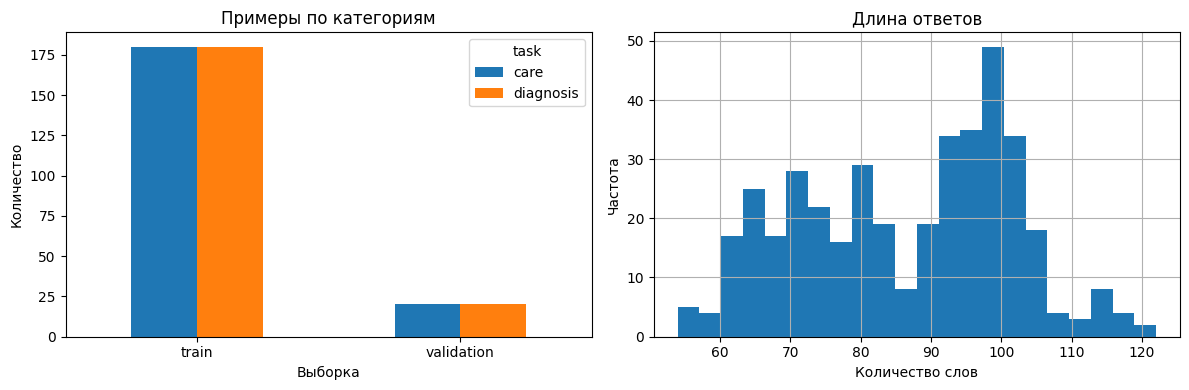

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
counts.plot(kind="bar", ax=axes[0], rot=0)
axes[0].set_title("Примеры по категориям")
axes[0].set_ylabel("Количество")
axes[0].set_xlabel("Выборка")

records_df["answer_words"].hist(bins=22, ax=axes[1])
axes[1].set_title("Длина ответов")
axes[1].set_xlabel("Количество слов")
axes[1].set_ylabel("Частота")

plt.tight_layout()
fig.savefig(RESULTS_DIR / "dataset_distributions.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Автоматические проверки

Проверяется, что диалог содержит ровно два непустых сообщения с ролями `user` и `assistant`, основной язык текста — русский, а ответ имеет обязательные разделы в нужном порядке. Для `care` требуются «Условия» и «Рекомендации»; для `diagnosis` — «Возможные причины», «Что проверить» и «Что делать».

Дополнительно проверяются уникальность нормализованных вопросов и ID, отсутствие известных посторонних вставок, наличие записей о происхождении и корректных ID источников. Вопросы SFT сопоставляются с 30 контрольными вопросами для выявления точных совпадений.

Эти проверки выявляют структурные ошибки и часть проблем с данными. Фактическая корректность рекомендаций требует отдельной содержательной оценки.


In [17]:
REQUIRED_HEADINGS = {
    "care": ["Условия", "Рекомендации"],
    "diagnosis": ["Возможные причины", "Что проверить", "Что делать"],
}
BAD_FRAGMENTS = ("iteDatabase", "SELECT * FROM", "<script", "www.google.com/search?")


def normalize(text: str) -> str:
    return " ".join(re.findall(r"\w+", text.casefold()))


def is_cyrillic(text: str) -> bool:
    letters = [ch for ch in text if ch.isalpha()]
    if not letters:
        return False
    cyrillic_count = sum("а" <= ch.lower() <= "я" or ch.lower() == "ё" for ch in letters)
    return cyrillic_count / len(letters) >= 0.60


def check_headings(answer: str, task: str) -> bool:
    positions = []
    for title in REQUIRED_HEADINGS[task]:
        pattern = rf"(?m)^\s*{re.escape(title)}\s*:?\s*$"
        matches = list(re.finditer(pattern, answer, flags=re.IGNORECASE))
        if len(matches) != 1:
            return False
        positions.append(matches[0])
    if [match.start() for match in positions] != sorted(match.start() for match in positions):
        return False
    for i, match in enumerate(positions):
        end = positions[i + 1].start() if i + 1 < len(positions) else len(answer)
        if not answer[match.end():end].strip():
            return False
    return True


def check_example(item: dict, task: str) -> list[str]:
    errors = []
    messages = item.get("messages")
    if not isinstance(messages, list) or len(messages) != 2:
        return ["messages must contain exactly two entries"]
    if [msg.get("role") for msg in messages] != ["user", "assistant"]:
        errors.append("roles must be user, assistant")
    question = messages[0].get("content", "")
    answer = messages[1].get("content", "")
    if not question.strip() or not answer.strip():
        errors.append("empty text")
    if not is_cyrillic(question) or not is_cyrillic(answer):
        errors.append("language check failed")
    if not check_headings(answer, task):
        errors.append("incorrect headings")
    if any(fragment.lower() in answer.lower() for fragment in BAD_FRAGMENTS):
        errors.append("unexpected text artifact")
    return errors

meta_by_split = {split: [m for m in metadata if m["split"] == split] for split in ("train", "validation")}
checks = []
for split, items in [("train", train), ("validation", validation)]:
    assert len(items) == len(meta_by_split[split]), "Количество метаданных не соответствует выборке"
    for i, (item, meta) in enumerate(zip(items, meta_by_split[split])):
        checks.append({"split": split, "id": meta["id"], "task": meta["task"],
                       "error": "; ".join(check_example(item, meta["task"]))})

check_df = pd.DataFrame(checks)
display(check_df[check_df["error"] != ""].head(20))
print("Ошибок в структуре:", (check_df["error"] != "").sum())

,split,id,task,error


Ошибок в структуре: 0


In [18]:
all_examples = train + validation
questions = [example["messages"][0]["content"] for example in all_examples]
normalized = [normalize(q) for q in questions]
eval_normalized = {normalize(q["question"]) for q in eval_questions}

assert len(set(normalized)) == len(normalized), "Обнаружены повторяющиеся обучающие вопросы"
assert not (set(normalized) & eval_normalized), "Обнаружено точное пересечение с тестовыми вопросами"
assert len({m["id"] for m in metadata}) == len(all_examples), "Повторяющиеся ID"

provenance_ids = set(provenance["id"])
source_ids = set(sources["source_id"])
assert provenance_ids == {m["id"] for m in metadata}, "Не все примеры имеют запись о происхождении"
assert all(set(m["source_ids"]) <= source_ids for m in metadata), "Неизвестный ID источника"
assert (check_df["error"] == "").all(), "Некоторые записи не прошли автоматические проверки"

print("Формат, язык, уникальность, источники и точные пересечения с eval: проверка пройдена")

Формат, язык, уникальность, источники и точные пересечения с eval: проверка пройдена


## 5. Сходство с контрольными вопросами

Для каждого вопроса SFT определяется наиболее похожий контрольный вопрос. Используется TF–IDF по символьным n-граммам длины 3–5 и косинусное сходство. Порог 0,85 служит основанием для дополнительного просмотра совпадающих формулировок.

В сохранённом расчёте максимальное сходство составляет около 0,455; пар с показателем не ниже 0,85 нет. Это подтверждает отсутствие близких совпадений по выбранной текстовой метрике, но не исключает смыслового сходства типичных ситуаций ухода. Таблица ближайших пар сохраняется в `results/dataset/eval_similarity_audit.csv`.


In [19]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5))
corpus = questions + [record["question"] for record in eval_questions]
features = vectorizer.fit_transform(corpus)
similarity = (features[:len(questions)] @ features[len(questions):].T).toarray()

pairs = []
for i in range(len(questions)):
    j = int(similarity[i].argmax())
    pairs.append({
        "sft_question": questions[i],
        "closest_eval_id": eval_questions[j]["id"],
        "closest_eval_question": eval_questions[j]["question"],
        "similarity": float(similarity[i, j]),
    })

similarities = pd.DataFrame(pairs).sort_values("similarity", ascending=False)
display(similarities.head(8))
print("Пары с сходством >= 0.85:", (similarities["similarity"] >= 0.85).sum())
similarities.to_csv(RESULTS_DIR / "eval_similarity_audit.csv", index=False)

,sft_question,closest_eval_id,closest_eval_question,similarity
352,"По каким признакам понять, что пора пересажива...",q03,"Как понять, что замиокулькас пора поливать зимой?",0.454610
179,После перестановки к яркому окну на листьях фи...,q04,У фикуса Бенджамина резко опадают листья после...,0.420932
152,На стебле пустынного кактуса видны светлые точ...,q28,На листьях плюща появилась мелкая светлая крап...,0.391221
271,"Как подкармливать хлорофитум, чтобы не перекор...",q09,"Как пересадить молодой хлорофитум, чтобы не по...",0.352049
180,"Как подкармливать замиокулькас, чтобы не перек...",q03,"Как понять, что замиокулькас пора поливать зимой?",0.342099
389,"У хойи новые листья стали мельче, а рост замед...",q10,У хлорофитума побледнели листья и замедлился р...,0.334671
395,"У антуриума новые листья стали мельче, а рост ...",q10,У хлорофитума побледнели листья и замедлился р...,0.331996
297,У замиокулькаса почти нет яркого дневного свет...,q03,"Как понять, что замиокулькас пора поливать зимой?",0.330294


Пары с сходством >= 0.85: 0


## 6. Выборка для содержательной проверки

Для ручного просмотра отбираются 24 примера: по 12 из каждой категории, с фиксированным `random_state=42`. Ниже выводятся первые шесть записей с вопросами, ответами и источниками.

Проверочная форма содержит поля `factually_correct`, `actionable` и `reviewer_notes`. Они предназначены для оценки фактической корректности, практической применимости и замечаний проверяющего. В сохранённом расчёте эти поля не заполнены; вывод примеров сам по себе не означает прохождения экспертной проверки. Форма записывается в `results/dataset/manual_review_sample.csv`.


In [20]:
review = (
    records_df.groupby("task", group_keys=False)
    .sample(n=12, random_state=42)
    .sort_values(["task", "id"])
)

for _, record in review.head(6).iterrows():
    print("=" * 85)
    print(record["id"], "|", record["task"], "|", record["plant"])
    print("Вопрос:", record["question"])
    print("Ответ:", record["answer"], sep="\n")
    print("Источники:", "; ".join(record["source_urls"]))

review_sheet = review[["id", "split", "task", "plant", "question", "answer"]].copy()
review_sheet["factually_correct"] = ""
review_sheet["actionable"] = ""
review_sheet["reviewer_notes"] = ""
review_sheet.to_csv(RESULTS_DIR / "manual_review_sample.csv", index=False, encoding="utf-8-sig")
print("Форма для ручной проверки:", RESULTS_DIR / "manual_review_sample.csv")

SFT-0002 | care | монстера
Вопрос: Зимой света становится меньше. Как скорректировать условия для растения «монстера»?
Ответ:
Условия:
- При сокращении светового дня поглощение воды обычно уменьшается, особенно в прохладной комнате.
- Для вида характерен такой режим полива: проверять подсыхание верхней части грунта и не оставлять воду в поддоне.

Рекомендации:
1. Перед каждым поливом проверяйте субстрат; зимой интервалы могут быть больше, чем летом.
2. Не ставьте горшок вплотную к холодному стеклу и горячей батарее.
3. Подкормку при замедлении роста сократите или временно прекратите, наблюдая за состоянием новых листьев.
Источники: https://www.rhs.org.uk/plants/swiss-cheese-plants/how-to-grow-swiss-cheese-plants; https://www.rhs.org.uk/plants/types/houseplants/growing-guide; https://www.extension.umd.edu/resource/watering-indoor-plants
SFT-0021 | care | замиокулькас
Вопрос: Недавно купил замиокулькас. Какие действия важны в период адаптации?
Ответ:
Условия:
- После покупки растение ада

## 7. Совместимость с Hugging Face Datasets

Файлы загружаются функцией `datasets.load_dataset` с форматом `json`. Успешная загрузка должна создать две выборки: `train` на 360 строк и `validation` на 40 строк, с полем `messages`.

Ячейка выводит структуру `DatasetDict` и первое сообщение обучающей выборки. Если библиотека `datasets` не установлена, вместо загрузки выводится инструкция по её установке.


In [21]:
try:
    from datasets import load_dataset
    dataset = load_dataset(
        "json",
        data_files={"train": str(DATA_DIR / "train.jsonl"),
                    "validation": str(DATA_DIR / "validation.jsonl")},
    )
    print(dataset)
    print("Первое сообщение:", dataset["train"][0]["messages"][0])
except ImportError:
    print("Для проверки в этом окружении установите datasets: %pip install datasets")

Generating train split: 0 examples [00:00, ? examples/s]

Generating validation split: 0 examples [00:00, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['messages'],
        num_rows: 360
    })
    validation: Dataset({
        features: ['messages'],
        num_rows: 40
    })
})
Первое сообщение: {'role': 'user', 'content': 'У хойи после перемещения на солнечный подоконник появились светлые сухие участки. Что предпринять?'}


## 8. Результаты проверки и сохранение отчёта

Подготовлен набор из 400 диалогов: 360 обучающих и 40 валидационных. Категории сбалансированы, представлены 25 растений и 24 типа сценариев. В выполненном расчёте структурных ошибок, повторяющихся нормализованных вопросов и точных совпадений с контрольным набором не обнаружено. По TF–IDF нет пар с контрольными вопросами выше порога 0,85. Загрузка обеих выборок в Hugging Face Datasets выполнена успешно.

Сводка проверок записывается в `results/dataset/dataset_audit.json`, распределение по выборкам и категориям — в `split_distribution.csv`. В том же каталоге сохраняются график `dataset_distributions.png`, таблица сходства и форма ручного просмотра. Обучающие файлы остаются в `data/`.

Автоматические результаты подтверждают техническую согласованность набора. Ограничения связаны с синтетическим, сценарным построением примеров и отсутствием полной независимой предметной проверки. Эти ограничения учитываются при интерпретации качества подготовленных данных.


In [22]:
summary = {
    "dataset_kind": "synthetic, curated, template-based",
    "total_examples": len(all_examples),
    "train_examples": len(train),
    "validation_examples": len(validation),
    "task_counts": counts.to_dict(orient="index"),
    "plant_count": records_df["plant"].nunique(),
    "scenario_count": records_df["scenario"].nunique(),
    "format_errors": int((check_df["error"] != "").sum()),
    "exact_eval_overlaps": int(len(set(normalized) & eval_normalized)),
    "high_similarity_pairs_threshold_0_85": int((similarities["similarity"] >= 0.85).sum()),
    "validation_method": "holdout of case types: vacation and pale_growth",
    "limitations": [
        "Synthetic examples are not an expert-verified gold standard.",
        "The fact references describe general growing principles, not proof for every sentence.",
        "Template reuse can reduce linguistic diversity.",
    ],
}
with (RESULTS_DIR / "dataset_audit.json").open("w", encoding="utf-8") as file:
    json.dump(summary, file, ensure_ascii=False, indent=2, default=str)

records_df.groupby(["split", "task"]).size().rename("count").reset_index().to_csv(
    RESULTS_DIR / "split_distribution.csv", index=False
)

print("Таблицы, проверочная выборка и графики сохранены в:", RESULTS_DIR)
print("Train:", DATA_DIR / "train.jsonl")
print("Validation:", DATA_DIR / "validation.jsonl")

Таблицы, проверочная выборка и графики сохранены в: /content/drive/MyDrive/plant-advisor/results/dataset
Train: /content/drive/MyDrive/plant-advisor/data/train.jsonl
Validation: /content/drive/MyDrive/plant-advisor/data/validation.jsonl
